# Prédiction du churn à 90 jours

Equipe 5, module Webmarketing et CRM (TDIA3). Suite du notebook `02_rfm_segmentation.ipynb`.

**Périmètre (étape 3).** Prédire quels clients n'achèteront pas dans les 90 jours suivant une date de référence. Comparaison d'une régression logistique, d'une forêt aléatoire et d'une règle simple fondée sur la récence, avec précision, rappel, F1, AUC et matrice de confusion. Les campagnes chiffrées ne sont pas traitées ici.

**Données.** Online Retail II (Chen, D., 2012, https://doi.org/10.24432/C5CG6D, CC BY 4.0), préparées par `python src/data_prep.py`.

**Ventes brutes.** Tous les montants sont des ventes brutes, retours non déduits. Les retours sont discutés en section 9.

## 1. Définition du churn et plan temporel

**Churn à 90 jours.** À une date de référence `T`, un client « actif » est un client qui a acheté au moins une fois avant `T`. Il est classé `churn = 1` s'il n'effectue **aucun achat** dans la fenêtre `[T, T + 90 jours)`. Un retour (facture `C*`) n'est pas un achat. C'est une inactivité, pas une résiliation : ce commerce n'a pas de contrat, le « départ » est une inférence.

**Variables.** Toutes calculées avec les seules lignes datées **avant** `T`. L'étiquette utilise la fenêtre suivante : variables et étiquette ne se chevauchent jamais.

**Plan temporel (marche en avant).** Chaque période d'entraînement a une étiquette entièrement connue avant la date de la période suivante :

* entraînement : 4 instantanés espacés de 3 mois (2010-06-01, 2010-09-01, 2010-12-01, 2011-03-01) ;
* validation : 2011-06-01, pour choisir les hyperparamètres et le seuil ;
* test : 2011-09-01, utilisé une seule fois à la fin. Sa fenêtre d'étiquette se termine le 2011-11-30, avant la fin des données (2011-12-09).

Un même client apparaît dans plusieurs instantanés avec des variables différentes. C'est normal en marche en avant : à chaque date, on n'utilise que ce qu'on savait à cette date. Les 90 jours de chaque étiquette de la période n+1 ne servent jamais à entraîner un modèle évalué sur la période n.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (adjusted_rand_score, average_precision_score, confusion_matrix,
                             precision_recall_fscore_support, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import churn as ch
import data_prep
import rfm as rfmlib

HORIZON = ch.HORIZON_DAYS
TRAIN_DATES = ["2010-06-01", "2010-09-01", "2010-12-01", "2011-03-01"]
VAL_DATE = "2011-06-01"
TEST_DATE = "2011-09-01"
SEED = 42
OUT_FIGS = ROOT / "reports" / "figures"; OUT_FIGS.mkdir(parents=True, exist_ok=True)
OUT_METRICS = ROOT / "reports" / "churn_metrics.csv"
OUT_SNAPSHOTS = ROOT / "reports" / "churn_snapshots.csv"
OUT_SEGMENTS = ROOT / "reports" / "churn_by_segment.csv"
OUT_RETURNS = ROOT / "reports" / "churn_returns_sensitivity.csv"
OUT_CONSISTENCY = ROOT / "reports" / "churn_threshold_consistency.csv"
OUT_CROSS = ROOT / "reports" / "churn_segments_nb02_vs_nb03.csv"
OUT_PREDS = ROOT / "data" / "processed" / "churn_test_predictions.parquet"
pd.set_option("display.width", 200, "display.max_columns", 40)

plan = ch.check_temporal_plan(TRAIN_DATES, VAL_DATE, TEST_DATE, HORIZON)
display(plan)

,role,date_reference,fin_fenetre_etiquette
0,entrainement,2010-06-01,2010-08-30
1,entrainement,2010-09-01,2010-11-30
2,entrainement,2010-12-01,2011-03-01
3,entrainement,2011-03-01,2011-05-30
4,validation,2011-06-01,2011-08-30
5,test,2011-09-01,2011-11-30


## 2. Chargement et contrôle de cohérence des données

In [2]:
assert data_prep.verify() == 0, "Les données ne correspondent pas au rapport : relancer python src/data_prep.py"
purchases = pd.read_parquet(ROOT / "data" / "processed" / "purchases.parquet")
returns = pd.read_parquet(ROOT / "data" / "processed" / "returns.parquet")
print(f"\nachats : {len(purchases):,} lignes ; retours : {len(returns):,} lignes ; "
      f"données jusqu'au {purchases.InvoiceDate.max():%Y-%m-%d %H:%M}")

OK    zip = valeur epinglee  (reference : 572E36277C2390FBFDE10664750731E0A86F55E33470D91919085F0408E67BFB)
OK    zip = rapport  (reference : 572E36277C2390FBFDE10664750731E0A86F55E33470D91919085F0408E67BFB)
OK    zip = manifeste  (reference : 572E36277C2390FBFDE10664750731E0A86F55E33470D91919085F0408E67BFB)
OK    xlsx = contenu du zip  (reference : BCBE73B35F5B7BABF197FB0CB983A11F5D9FF929078D4AA53D171B1F2DF2E980)
OK    xlsx = rapport  (reference : BCBE73B35F5B7BABF197FB0CB983A11F5D9FF929078D4AA53D171B1F2DF2E980)
OK    xlsx = manifeste  (reference : BCBE73B35F5B7BABF197FB0CB983A11F5D9FF929078D4AA53D171B1F2DF2E980)
OK    raw.parquet = manifeste  (reference : 121686E90C9CEEBDA6F38B802C0D2118887053AB2698ABD5BAC97F68D44F00CE)
OK    schema du cache a jour  (reference : 2)
OK    raw.parquet : lignes = rapport  (reference : 1067371)
OK    purchases.parquet : lignes = rapport  (reference : 788127)
OK    returns.parquet : lignes = rapport  (reference : 17641)
OK    raw.parquet : SHA-256 = rappo

## 3. Construction des instantanés : effectifs et taux de churn

Variables calculées à `T` (colonnes de `src/churn.py`) : récence, fréquence, montant brut, ancienneté, panier moyen, écart moyen entre deux factures, rapport récence / écart moyen, factures et dépenses sur les 90 derniers jours, factures sur les 90 jours précédents, nombre de produits distincts, pays de la dernière commande (Royaume-Uni ou non).

Population d'un instantané : tous les clients identifiés ayant acheté au moins une fois avant `T`.

In [3]:
dates = TRAIN_DATES + [VAL_DATE, TEST_DATE]
snap = {d: ch.build_snapshot(purchases, returns, d, HORIZON) for d in dates}
train = pd.concat([snap[d] for d in TRAIN_DATES])
val, test = snap[VAL_DATE], snap[TEST_DATE]
train_val = pd.concat([train, val])

rows = []
for d, role in zip(dates, plan.role):
    s = snap[d]
    rows.append({"rôle": role, "date_référence": d, "fin_fenêtre_étiquette": (pd.Timestamp(d) + pd.Timedelta(days=HORIZON)).date(),
                 "clients": len(s), "churn": int(s.churn.sum()), "taux_churn": round(s.churn.mean(), 4),
                 "clients_actifs_180j": int((s.recency_days <= 180).sum()),
                 "taux_churn_actifs_180j": round(s.loc[s.recency_days <= 180, "churn"].mean(), 4)})
snapshots = pd.DataFrame(rows)
snapshots.to_csv(OUT_SNAPSHOTS, index=False)
display(snapshots)
print(f"Entraînement : {len(train):,} lignes (4 instantanés) | validation : {len(val):,} | test : {len(test):,}")
print("Valeurs manquantes (test) :", test[ch.BASE_FEATURES + ch.BINARY_FEATURES].isna().sum().loc[lambda s: s > 0].to_dict())

,rôle,date_référence,fin_fenêtre_étiquette,clients,churn,taux_churn,clients_actifs_180j,taux_churn_actifs_180j
0,entrainement,2010-06-01,2010-08-30,2684,1350,0.5030,2672,0.5019
1,entrainement,2010-09-01,2010-11-30,3299,1375,0.4168,2831,0.3797
2,entrainement,2010-12-01,2011-03-01,4239,2832,0.6681,3471,0.6197
3,entrainement,2011-03-01,2011-05-30,4512,2927,0.6487,3348,0.5774
4,validation,2011-06-01,2011-08-30,4908,3291,0.6705,2688,0.5037
5,test,2011-09-01,2011-11-30,5224,2988,0.5720,2780,0.3942


Entraînement : 14,734 lignes (4 instantanés) | validation : 4,908 | test : 5,224
Valeurs manquantes (test) : {'mean_gap_days': 1582, 'overdue_ratio': 1582}


**Lecture.**

* Le taux de churn varie beaucoup d'un instantané à l'autre : 41,7 % pour la fenêtre septembre à novembre 2010, 66,8 % pour décembre 2010 à février 2011, 67,1 % pour la validation et **57,2 % pour le test** (2 988 clients sur 5 224). Le taux de base de la validation est donc 10 points au-dessus de celui du test. Cette instabilité justifie le choix d'un seuil qui ne dépend pas du taux de churn (section 5).
* Le premier instantané (2010-06-01) ne compte que 2 684 clients : les données commencent le 2009-12-01, soit six mois d'historique seulement. L'ancienneté et la fréquence des premiers instantanés sont tronquées à gauche.
* Seuls 2 780 clients du test (53 %) ont acheté dans les 180 jours précédents ; leur taux de churn est de 39,4 %. Les autres sont presque tous inactifs, ce qui rend leur classement facile (section 6).

### Tests d'absence de fuite

1. Les **variables** sont identiques si on falsifie toutes les lignes datées de `T` ou après (achats et retours).
2. Les **étiquettes** sont identiques si on falsifie les lignes datées de `T + 90 jours` ou après.
3. Les étiquettes **changent** bien si on falsifie la fenêtre `[T, T + 90 j)` : elles dépendent de cette fenêtre et d'elle seule.
4. Un instantané dont la fenêtre dépasse les données est refusé.
5. Le plan temporel est validé par `check_temporal_plan` (section 1) : aucune étiquette d'une période n'est connue après la date de la période suivante.

In [4]:
for d in [TRAIN_DATES[0], VAL_DATE, TEST_DATE]:
    T0, T1 = pd.Timestamp(d), pd.Timestamp(d) + pd.Timedelta(days=HORIZON)
    ref = snap[d]

    # 1. variables : falsifier tout ce qui est >= T
    p2, r2 = purchases.copy(), returns.copy()
    fp, fr = p2.InvoiceDate >= T0, r2.InvoiceDate >= T0
    p2.loc[fp, "montant_brut_gbp"] *= 1000; p2.loc[fp, "customer_id"] += 1; p2.loc[fp, "StockCode"] = "ZZZ"
    r2.loc[fr, "montant_retour_gbp"] *= 1000; r2.loc[fr, "customer_id"] += 1
    f2 = ch.build_features(p2, r2, d)
    pd.testing.assert_frame_equal(f2, ref[f2.columns])

    # 2. étiquettes : falsifier tout ce qui est >= T + 90 j
    p3 = purchases.copy(); late = p3.InvoiceDate >= T1; p3.loc[late, "customer_id"] += 1
    pd.testing.assert_series_equal(ch.build_labels(p3, ref.index, d, HORIZON), ref["churn"])

    # 3. étiquettes : retirer la fenêtre [T, T+90) rend tout le monde churn = 1
    p4 = purchases[~((purchases.InvoiceDate >= T0) & (purchases.InvoiceDate < T1))]
    assert ch.build_labels(p4, ref.index, d, HORIZON).eq(1).all()

try:
    ch.build_labels(purchases, test.index, "2011-10-15", HORIZON)
    raise AssertionError("test 4 échoué : la fenêtre hors données aurait dû être refusée")
except ValueError as e:
    print("Test 4 : fenêtre hors données refusée :", str(e)[:90], "...")
print("Tests 1, 2 et 3 réussis pour les instantanés", [TRAIN_DATES[0], VAL_DATE, TEST_DATE])

Test 4 : fenêtre hors données refusée : La fenetre d'etiquette [2011-10-15, 2012-01-13) depasse les donnees (fin : 2011-12-10). ...
Tests 1, 2 et 3 réussis pour les instantanés ['2010-06-01', '2011-06-01', '2011-09-01']


## 4. Règle de référence : la récence seule

Règle : « un client est prédit churn si sa récence dépasse `r` jours ». Le seuil `r` est choisi **sur la validation** avec le même critère que pour les modèles (indice de Youden, voir section 5), puis appliqué tel quel au test. L'AUC de la récence, utilisée comme score, mesure ce que la récence seule sait déjà séparer.

In [5]:
def metrics(y, score, thr):
    y, score = np.asarray(y), np.asarray(score, dtype=float)
    pred = (score >= thr).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    top = np.argsort(-score, kind="stable")[: int(round(0.2 * len(y)))]          # 20 % de clients les plus à risque
    in_unit = score.min() >= 0 and score.max() <= 1 and len(np.unique(score)) > 2
    return {"seuil": thr, "précision": p, "rappel": r, "f1": f, "auc": roc_auc_score(y, score),
            "auc_pr": average_precision_score(y, score), "précision_top20": y[top].mean(),
            "brier": float(np.mean((score - y) ** 2)) if in_unit else np.nan,
            "tn": tn, "fp": fp, "fn": fn, "tp": tp,
            "part_prédite_churn": pred.mean(), "taux_churn": float(y.mean()), "clients": len(y)}

def best_threshold(y, score, grid):
    """Seuil qui maximise l'indice de Youden (rappel + spécificité - 1). Ne dépend pas du taux de churn."""
    y = np.asarray(y)
    def youden(t):
        m = metrics(y, score, t)
        return m["rappel"] + m["tn"] / (m["tn"] + m["fp"]) - 1
    return grid[int(np.argmax([youden(t) for t in grid]))]
rule_grid = [r + 1 for r in range(0, 700, 5)]       # recency_days >= r+1  <=>  recency_days > r
rule_thr = best_threshold(val.churn, val.recency_days, rule_grid)
print(f"Règle de récence : prédit churn si récence > {rule_thr - 1:.0f} jours (choisi sur la validation)")
res = {"Tous prédits churn": {"validation": metrics(val.churn, np.ones(len(val)), 0.5), "test": metrics(test.churn, np.ones(len(test)), 0.5)},
       "Règle de récence": {"validation": metrics(val.churn, val.recency_days, rule_thr),
                            "test": metrics(test.churn, test.recency_days, rule_thr)}}
pd.DataFrame({k: pd.Series(v) for k, v in res["Règle de récence"].items()}).T[["seuil", "précision", "rappel", "f1", "auc"]].round(3)

Règle de récence : prédit churn si récence > 105 jours (choisi sur la validation)


,seuil,précision,rappel,f1,auc
validation,106.0,0.839,0.706,0.767,0.774
test,106.0,0.734,0.764,0.749,0.760


## 5. Modèles : préparation, sélection, seuil

**Préparation (ajustée sur l'entraînement uniquement, dans un `Pipeline`).**

* imputation par la médiane (l'écart moyen entre factures est manquant pour les clients à une seule facture) avec indicateur de valeur manquante ;
* régression logistique : `log(1 + x)` puis standardisation des variables continues ; la variable binaire (Royaume-Uni) passe telle quelle ;
* forêt aléatoire : pas de transformation (insensible à l'échelle).

**Sélection.** Les hyperparamètres sont choisis par l'AUC sur la validation (les modèles sont ajustés sur l'entraînement). En cas d'égalité à 0,0005 près, on garde la configuration la plus simple. Le **seuil de décision** maximise l'indice de Youden (rappel + spécificité - 1) sur la validation : il ne dépend pas du taux de churn, qui varie fortement d'un trimestre à l'autre (de 42 % à 67 %). Un seuil qui maximise le F1 a été essayé en premier et abandonné : quand plus de la moitié des clients sont churn, il tend vers « tout le monde est churn » (voir section 6). Les modèles sont ensuite **ré-ajustés sur entraînement + validation** et appliqués au test avec le seuil choisi : le test n'a servi à aucun choix.

In [6]:
def make_lr(C, feats):
    num = [f for f in feats if f not in ch.BINARY_FEATURES]
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                          ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                          ("sc", StandardScaler())]), num),
        ("bin", "passthrough", [f for f in feats if f in ch.BINARY_FEATURES])])
    return Pipeline([("pre", pre), ("model", LogisticRegression(C=C, max_iter=2000))])

def make_rf(depth, leaf, feats):
    pre = ColumnTransformer([("num", SimpleImputer(strategy="median", add_indicator=True), feats)])
    return Pipeline([("pre", pre), ("model", RandomForestClassifier(
        n_estimators=300, max_depth=depth, min_samples_leaf=leaf, random_state=SEED, n_jobs=1))])

# listes ordonnées du plus simple au plus complexe
LR_GRID = [{"C": C} for C in (0.01, 0.1, 1, 10)]
RF_GRID = [{"depth": d, "leaf": l} for d in (5, 10, None) for l in (20, 5)]
THR_GRID = [round(t, 2) for t in np.arange(0.05, 0.951, 0.01)]

def run_models(feats, label=""):
    """Sélection sur la validation, ré-ajustement sur entraînement + validation, évaluation sur le test."""
    out, fitted = {}, {}
    for name, make, grid in [("Régression logistique", make_lr, LR_GRID), ("Forêt aléatoire", make_rf, RF_GRID)]:
        scores = []
        for g in grid:
            m = make(*g.values(), feats).fit(train[feats], train.churn)
            scores.append(roc_auc_score(val.churn, m.predict_proba(val[feats])[:, 1]))
        best = max(scores)
        pick = next(i for i, s in enumerate(scores) if s >= best - 0.0005)
        params = grid[pick]
        m_val = make(*params.values(), feats).fit(train[feats], train.churn)
        p_val = m_val.predict_proba(val[feats])[:, 1]
        thr = best_threshold(val.churn, p_val, THR_GRID)
        m_final = make(*params.values(), feats).fit(train_val[feats], train_val.churn)
        p_test = m_final.predict_proba(test[feats])[:, 1]
        out[name] = {"params": params, "grid_auc_validation": [round(s, 4) for s in scores], "seuil": thr,
                     "validation": metrics(val.churn, p_val, thr), "test": metrics(test.churn, p_test, thr),
                     "p_test": p_test, "p_val": p_val,
                     "p_test_valmodel": m_val.predict_proba(test[feats])[:, 1]}
        fitted[name] = m_final
    return out, fitted

FEATS = ch.BASE_FEATURES + ch.BINARY_FEATURES
models, fitted = run_models(FEATS)
for name, r in models.items():
    print(f"{name} : paramètres {r['params']} | AUC validation par configuration {r['grid_auc_validation']} | seuil {r['seuil']:.2f}")

Régression logistique : paramètres {'C': 0.1} | AUC validation par configuration [0.8207, 0.8213, 0.8213, 0.8213] | seuil 0.59
Forêt aléatoire : paramètres {'depth': 5, 'leaf': 20} | AUC validation par configuration [0.8219, 0.8219, 0.818, 0.8158, 0.8162, 0.807] | seuil 0.58


## 6. Résultats sur le test (2011-09-01, fenêtre jusqu'au 2011-11-30)

Précision, rappel et F1 sont ceux de la classe « churn ». Le seuil vient de la validation. « Tous prédits churn » est la référence triviale : sa précision égale le taux de churn, son rappel est de 1.

In [7]:
res.update({name: {"validation": r["validation"], "test": r["test"]} for name, r in models.items()})
order = ["Tous prédits churn", "Règle de récence", "Régression logistique", "Forêt aléatoire"]
table = pd.DataFrame({m: res[m]["test"] for m in order}).T
display(table[["seuil", "précision", "rappel", "f1", "auc", "auc_pr", "précision_top20", "brier", "part_prédite_churn"]].round(3))
print(f"Taux de churn réel au test : {test.churn.mean():.1%} sur {len(test):,} clients")
print("\nValidation (modèles ajustés sur l'entraînement seul, seuil choisi ici) :")
display(pd.DataFrame({m: res[m]["validation"] for m in order}).T[["seuil", "précision", "rappel", "f1", "auc", "précision_top20", "taux_churn"]].round(3))

rows = []
for m in order:
    for split in ("validation", "test"):
        rows.append({"modèle": m, "jeu": split, **res[m][split]})
pd.DataFrame(rows).round(4).to_csv(OUT_METRICS, index=False, encoding="utf-8")

,seuil,précision,rappel,f1,auc,auc_pr,précision_top20,brier,part_prédite_churn
Tous prédits churn,0.50,0.572,1.000,0.728,0.500,0.572,0.557,NaN,1.000
Règle de récence,106.00,0.734,0.764,0.749,0.760,0.801,0.869,NaN,0.595
Régression logistique,0.59,0.723,0.865,0.788,0.795,0.808,0.869,0.187,0.685
Forêt aléatoire,0.58,0.722,0.857,0.784,0.797,0.821,0.873,0.186,0.679


Taux de churn réel au test : 57.2% sur 5,224 clients

Validation (modèles ajustés sur l'entraînement seul, seuil choisi ici) :


,seuil,précision,rappel,f1,auc,précision_top20,taux_churn
Tous prédits churn,0.50,0.671,1.000,0.803,0.500,0.657,0.671
Règle de récence,106.00,0.839,0.706,0.767,0.774,0.910,0.671
Régression logistique,0.59,0.832,0.830,0.831,0.821,0.937,0.671
Forêt aléatoire,0.58,0.834,0.833,0.834,0.822,0.934,0.671


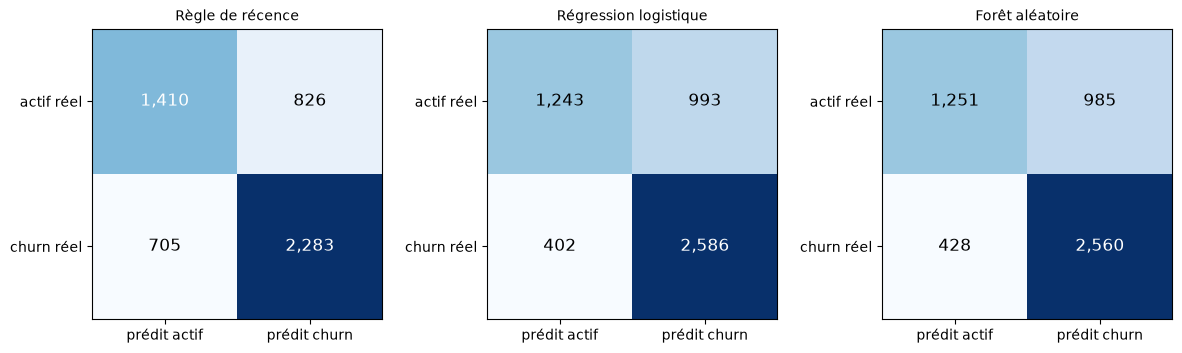

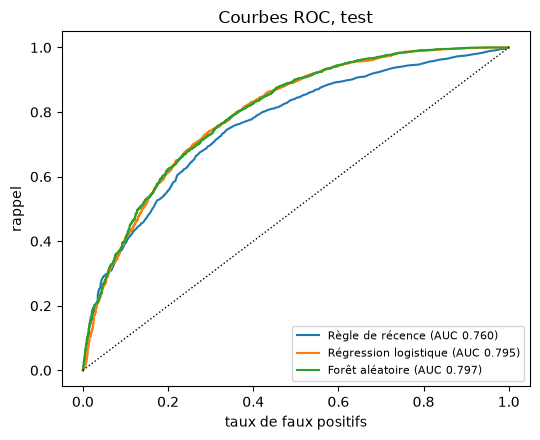

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, m in zip(axes, order[1:]):
    r = res[m]["test"]
    cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
    ax.set_xticks([0, 1], ["prédit actif", "prédit churn"]); ax.set_yticks([0, 1], ["actif réel", "churn réel"]); ax.set_title(m, fontsize=10)
plt.tight_layout(); fig.savefig(OUT_FIGS / "churn_matrices_confusion.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
scores_test = {"Règle de récence": test.recency_days.values,
               "Régression logistique": models["Régression logistique"]["p_test"],
               "Forêt aléatoire": models["Forêt aléatoire"]["p_test"]}
for m, s in scores_test.items():
    fpr, tpr, _ = roc_curve(test.churn, s); ax.plot(fpr, tpr, label=f"{m} (AUC {res[m]['test']['auc']:.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("taux de faux positifs"); ax.set_ylabel("rappel"); ax.legend(fontsize=8); ax.set_title("Courbes ROC, test")
plt.tight_layout(); fig.savefig(OUT_FIGS / "churn_roc.png", dpi=120); plt.show()

**Lecture (test, 5 224 clients, 57,2 % de churn).**

| | Précision | Rappel | F1 | AUC |
|---|---:|---:|---:|---:|
| Tous prédits churn (référence triviale) | 0,572 | 1,000 | 0,728 | 0,500 |
| Règle de récence (> 105 jours) | 0,734 | 0,764 | 0,749 | 0,760 |
| Régression logistique (seuil 0,59) | 0,723 | 0,865 | 0,788 | 0,795 |
| Forêt aléatoire (seuil 0,58) | 0,722 | 0,857 | 0,784 | 0,797 |

* Les deux modèles ont un meilleur AUC que la règle de récence (+0,035 et +0,037) et un meilleur F1 (+0,04). Le gain vient du **rappel** (0,86 contre 0,76) : ils repèrent plus de clients qui partent. Leur **précision** est légèrement inférieure à celle de la règle (0,72 contre 0,73) : à ce seuil, il n'y a pas de domination stricte.
* Le F1 flatte la classe majoritaire : prédire « churn » pour tout le monde donne déjà 0,728. Le gain réel des modèles en F1 est de +0,06. L'AUC est plus parlante.
* **Dans les 20 % de clients les plus à risque, la règle de récence est aussi bonne que les modèles** (précision de 0,869, 0,869 et 0,873 pour la règle, la logistique et la forêt). L'apport des modèles est ailleurs : au milieu du classement et chez les clients encore actifs (voir plus bas).
* Entre validation et test, la précision passe de 0,83 à 0,72 et le F1 de 0,83 à 0,79 pour les modèles : le seuil a été fixé quand 67 % des clients partaient, il est appliqué quand 57 % partent. Voir les limites.
* Les matrices de confusion et les nombres exacts (vrais et faux positifs et négatifs) sont dans la figure ci-dessus et dans `reports/churn_metrics.csv`.

### Incertitude : intervalles bootstrap et différences appariées

500 rééchantillonnages de clients du test (graine fixe). Les prédictions sont fixes : on mesure l'incertitude due à la composition du test, pas celle de l'entraînement.

In [9]:
rng = np.random.default_rng(SEED)
y = test.churn.values
compared = order[1:]   # sans la référence triviale
preds = {m: (np.asarray(scores_test[m]) >= res[m]["test"]["seuil"]).astype(int) for m in compared}
B = 500
boot = {m: {"auc": [], "f1": []} for m in compared}
diffs = {k: [] for k in ["LR - règle", "RF - règle", "RF - LR"]}
for _ in range(B):
    idx = rng.integers(0, len(y), len(y))
    yb = y[idx]
    a = {}
    for m in compared:
        a[m] = roc_auc_score(yb, np.asarray(scores_test[m])[idx])
        boot[m]["auc"].append(a[m])
        boot[m]["f1"].append(precision_recall_fscore_support(yb, preds[m][idx], average="binary", zero_division=0)[2])
    diffs["LR - règle"].append(a["Régression logistique"] - a["Règle de récence"])
    diffs["RF - règle"].append(a["Forêt aléatoire"] - a["Règle de récence"])
    diffs["RF - LR"].append(a["Forêt aléatoire"] - a["Régression logistique"])

ci = lambda v: f"[{np.percentile(v, 2.5):.3f} ; {np.percentile(v, 97.5):.3f}]"
display(pd.DataFrame({m: {"AUC": f"{res[m]['test']['auc']:.3f}", "IC95 AUC": ci(boot[m]["auc"]),
                          "F1": f"{res[m]['test']['f1']:.3f}", "IC95 F1": ci(boot[m]["f1"])} for m in compared}).T)
display(pd.DataFrame({k: {"écart d'AUC moyen": f"{np.mean(v):+.3f}", "IC95": ci(v)} for k, v in diffs.items()}).T)

,AUC,IC95 AUC,F1,IC95 F1
Règle de récence,0.760,[0.747 ; 0.774],0.749,[0.736 ; 0.761]
Régression logistique,0.795,[0.782 ; 0.807],0.788,[0.776 ; 0.798]
Forêt aléatoire,0.797,[0.785 ; 0.810],0.784,[0.771 ; 0.794]


,écart d'AUC moyen,IC95
LR - règle,+0.035,[0.028 ; 0.043]
RF - règle,+0.037,[0.030 ; 0.044]
RF - LR,+0.003,[-0.000 ; 0.006]


**Lecture.**

* Les intervalles à 95 % de l'AUC sont proches : règle [0,747 ; 0,774], logistique [0,782 ; 0,807], forêt [0,785 ; 0,810]. Les deux modèles sont nettement au-dessus de la règle (écarts [0,028 ; 0,043] et [0,030 ; 0,044], zéro exclu).
* **La forêt et la régression logistique ne se distinguent pas** : écart d'AUC de +0,003, intervalle [-0,000 ; 0,006].
* Ces intervalles ne mesurent que la variabilité du jeu de test. Ils ne disent rien sur la variabilité d'une période à l'autre : un seul test (automne 2011) a été évalué.
* **Clients encore actifs** (2 780 clients, récence ≤ 180 jours, 39,4 % de churn) : AUC de 0,658 pour la règle contre 0,764 (logistique) et 0,763 (forêt). Le rappel passe de 0,357 à 0,642 et 0,609, avec une précision comparable (0,59 à 0,61). C'est là que les modèles apportent le plus : repérer les clients encore actifs qui vont partir, ceux qu'on peut encore retenir.

### Clients encore actifs

Les clients dont le dernier achat date de plus de 180 jours sont presque tous classés churn : les séparer est facile et peu utile. L'AUC restreinte aux clients dont la récence est d'au plus 180 jours est une mesure plus exigeante.

In [10]:
act = (test.recency_days <= 180).values
rows = []
for m in compared:
    s = np.asarray(scores_test[m])
    rows.append({"modèle": m, "clients": int(act.sum()), "taux_churn": round(y[act].mean(), 3),
                 "auc": round(roc_auc_score(y[act], s[act]), 3),
                 "précision": round(precision_recall_fscore_support(y[act], preds[m][act], average="binary", zero_division=0)[0], 3),
                 "rappel": round(precision_recall_fscore_support(y[act], preds[m][act], average="binary", zero_division=0)[1], 3)})
active_table = pd.DataFrame(rows).set_index("modèle")
display(active_table)

,clients,taux_churn,auc,précision,rappel
modèle,,,,,
Règle de récence,2780,0.394,0.658,0.588,0.357
Régression logistique,2780,0.394,0.764,0.613,0.642
Forêt aléatoire,2780,0.394,0.763,0.607,0.609


### Cohérence entre le seuil et le modèle ré-ajusté

Le seuil est choisi sur la validation avec un modèle ajusté sur l'entraînement seul. Le modèle final est ensuite ré-ajusté sur entraînement + validation, puis évalué avec le **même** seuil. Si ce ré-ajustement déplaçait beaucoup les probabilités, le seuil ne serait plus adapté. On compare donc, sur le test, le modèle qui a servi à choisir le seuil et le modèle final.

Les deux dernières colonnes sont des **diagnostics** : l'indice de Youden J au seuil retenu, et le J maximal qu'on obtiendrait en choisissant le seuil sur le test lui-même. Cette seconde valeur n'est jamais utilisée pour un choix ; elle mesure seulement ce que coûte le décalage du taux de churn entre validation et test.

In [11]:
def youden_j(y, s, t):
    m = metrics(y, s, t)
    return m["rappel"] + m["tn"] / (m["tn"] + m["fp"]) - 1

rows, rhos = [], {}
for name in ["Régression logistique", "Forêt aléatoire"]:
    r = models[name]
    rhos[name] = pd.Series(r["p_test_valmodel"]).corr(pd.Series(r["p_test"]), method="spearman")
    for label, s in [("entraînement seul", r["p_test_valmodel"]), ("entraînement + validation (final)", r["p_test"])]:
        m = metrics(test.churn, s, r["seuil"])
        rows.append({"modèle": name, "ajusté sur": label, "seuil": r["seuil"], "auc": m["auc"], "précision": m["précision"],
                     "rappel": m["rappel"], "f1": m["f1"], "part_prédite_churn": m["part_prédite_churn"],
                     "proba_moyenne": float(np.mean(s)), "J_seuil_retenu": youden_j(test.churn, s, r["seuil"]),
                     "J_max_sur_test (diagnostic)": max(youden_j(test.churn, s, t) for t in THR_GRID)})
consistency = pd.DataFrame(rows)
display(consistency.round(3))
consistency.round(4).to_csv(OUT_CONSISTENCY, index=False, encoding="utf-8")
lr_r = models["Régression logistique"]
print("Corrélation de rang (Spearman) entre les deux versions sur le test :", {k: round(v, 4) for k, v in rhos.items()})
print(f"Validation, modèle ajusté sur l'entraînement : part prédite churn = {(lr_r['p_val'] >= lr_r['seuil']).mean():.1%}, "
      f"probabilité moyenne = {lr_r['p_val'].mean():.1%}, churn réel = {val.churn.mean():.1%}")

,modèle,ajusté sur,seuil,auc,précision,rappel,f1,part_prédite_churn,proba_moyenne,J_seuil_retenu,J_max_sur_test (diagnostic)
0,Régression logistique,entraînement seul,0.59,0.794,0.728,0.852,0.785,0.669,0.636,0.427,0.443
1,Régression logistique,entraînement + validation (final),0.59,0.795,0.723,0.865,0.788,0.685,0.653,0.421,0.444
2,Forêt aléatoire,entraînement seul,0.58,0.797,0.726,0.850,0.783,0.670,0.634,0.421,0.450
3,Forêt aléatoire,entraînement + validation (final),0.58,0.797,0.722,0.857,0.784,0.679,0.650,0.416,0.440


Corrélation de rang (Spearman) entre les deux versions sur le test : {'Régression logistique': np.float64(0.9987), 'Forêt aléatoire': np.float64(0.9927)}
Validation, modèle ajusté sur l'entraînement : part prédite churn = 66.9%, probabilité moyenne = 63.3%, churn réel = 67.1%


**Lecture.**

* Le modèle ré-ajusté et celui qui a servi à choisir le seuil classent presque de la même façon les clients du test : corrélation de rang de 0,9987 (logistique) et 0,9927 (forêt).
* Avec le même seuil, la part de clients prédits churn passe de 66,9 % à 68,5 % pour la logistique et de 67,0 % à 67,9 % pour la forêt. L'AUC passe de 0,794 à 0,795 (logistique) et reste à 0,797 (forêt) ; le F1 de 0,785 à 0,788 (logistique) et de 0,783 à 0,784 (forêt).
* La probabilité moyenne monte de 1,7 point (63,6 % à 65,3 %, logistique) quand la validation, à 67 % de churn, entre dans l'entraînement. Le seuil est donc très légèrement plus permissif sur le modèle final. L'écart est faible mais il existe.
* Le décalage qui compte vient du taux de churn, pas du ré-ajustement. À la validation, la probabilité moyenne (63,3 %) était proche du churn réel (67,1 %). Au test, elle est de 65,3 % pour un churn réel de 57,2 %. Diagnostic : choisir le seuil sur le test lui-même augmenterait l'indice de Youden de 0,02 à 0,03 (0,42 à 0,44 ou 0,45). Cette valeur n'est pas utilisée.
* **Conclusion.** Appliquer le seuil de la validation au modèle ré-ajusté est cohérent à cette précision. Évaluer le modèle ajusté sur l'entraînement seul (avec exactement le modèle qui a fixé le seuil) donne des résultats quasi identiques, visibles dans le tableau. On garde le modèle ré-ajusté, qui utilise le plus de données.

## 7. Ce que les modèles utilisent

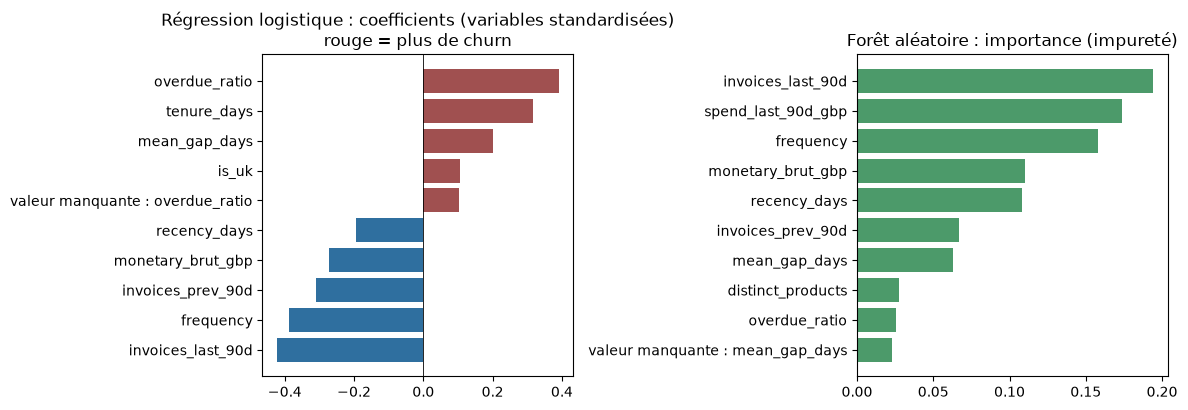

Coefficients les plus forts (logistique) : {'invoices_last_90d': -0.42, 'overdue_ratio': 0.39, 'frequency': -0.39, 'tenure_days': 0.32, 'invoices_prev_90d': -0.31}
Importances les plus fortes (forêt) : {'invoices_last_90d': 0.194, 'spend_last_90d_gbp': 0.174, 'frequency': 0.158, 'monetary_brut_gbp': 0.11, 'recency_days': 0.108}


In [12]:
lr = fitted["Régression logistique"]
names_lr = lr.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr.named_steps["model"].coef_[0], index=names_lr).sort_values()
rf = fitted["Forêt aléatoire"]
names_rf = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names_rf).sort_values()
clean = lambda s: s.replace("num__", "").replace("bin__", "").replace("missingindicator_", "valeur manquante : ")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
c = coef.reindex(coef.abs().sort_values(ascending=False).index[:10]).sort_values()
axes[0].barh([clean(i) for i in c.index], c.values, color=np.where(c.values > 0, "#a05050", "#2f6f9f"))
axes[0].set_title("Régression logistique : coefficients (variables standardisées)\nrouge = plus de churn"); axes[0].axvline(0, color="k", lw=.6)
i = imp.tail(10); axes[1].barh([clean(k) for k in i.index], i.values, color="#4c9a6a"); axes[1].set_title("Forêt aléatoire : importance (impureté)")
plt.tight_layout(); fig.savefig(OUT_FIGS / "churn_variables.png", dpi=120); plt.show()
print("Coefficients les plus forts (logistique) :", {clean(k): round(v, 2) for k, v in c.sort_values(key=abs, ascending=False).head(5).items()})
print("Importances les plus fortes (forêt) :", {clean(k): round(v, 3) for k, v in imp.tail(5)[::-1].items()})

**Lecture.**

* Les deux modèles s'appuient d'abord sur l'activité récente. Logistique, coefficients les plus forts : factures sur les 90 derniers jours (-0,42), rapport récence / écart habituel (+0,39), fréquence (-0,39), ancienneté (+0,32), factures sur les 90 jours précédents (-0,31). Forêt, importances : factures sur 90 jours (0,194), dépenses sur 90 jours (0,174), fréquence (0,158), montant brut (0,110), récence (0,108).
* Un client en retard par rapport à son propre rythme d'achat (`overdue_ratio` élevé) a plus de risque de partir. C'est l'apport principal par rapport à la récence seule.
* Les variables sont corrélées entre elles (la récence entre dans le calcul de overdue_ratio, la fréquence dans celui de l'écart moyen). Les coefficients pris isolément sont donc peu fiables : la récence a un coefficient **négatif** (-0,20) alors que, seule, elle augmente le risque de départ ; son effet passe par overdue_ratio. Il faut lire les coefficients ensemble, pas un par un.
* Le signe positif de l'ancienneté, à activité égale, est à manier avec prudence : l'ancienneté est tronquée à gauche (données depuis décembre 2009) et corrélée aux autres variables.
* Ces lectures sont des corrélations, pas des causes. L'importance par impureté de la forêt favorise les variables continues.

## 8. Segmentation ajustée sur l'entraînement et lien avec le churn

Les segments ne sont **pas** une variable d'entrée des modèles : ils sont calculés à partir de R, F et M, que les modèles voient déjà directement. Ils servent à lire le churn par groupe de clients et à relier ce notebook à `02_rfm_segmentation.ipynb`.

Pour éviter toute fuite, le `Segmenter` (standardisation + K-means à 4 clusters, graine 42) est **ajusté sur les lignes d'entraînement et de validation seulement**, puis appliqué au test sans être ré-ajusté. Les noms sont attribués par la règle du notebook 02, appliquée aux données d'entraînement.

In [13]:
seg = rfmlib.Segmenter(k=4, seed=SEED).fit(train_val[rfmlib.RFM_COLUMNS])
test_seg = seg.predict(test[rfmlib.RFM_COLUMNS])
assert seg.kmeans_.labels_.shape[0] == len(train_val) and set(train_val.snapshot_date) <= {pd.Timestamp(d) for d in TRAIN_DATES + [VAL_DATE]}
print("Segmenter ajusté sur", len(train_val), "lignes datées du", train_val.snapshot_date.min().date(), "au", train_val.snapshot_date.max().date(),
      "; noms :", seg.names_)

best_model = "Régression logistique"   # modèle retenu (voir « Choix du modèle »)
p_best = models[best_model]["p_test"]
tab = pd.DataFrame({"segment": test_seg.values, "churn": test.churn.values, "p": p_best,
                    "pred": (p_best >= models[best_model]["test"]["seuil"]).astype(int)}, index=test.index)
by_seg = tab.groupby("segment").agg(clients=("churn", "size"), taux_churn_réel=("churn", "mean"),
                                    proba_moyenne=("p", "mean"), part_prédite_churn=("pred", "mean")).loc[rfmlib.SEGMENT_ORDER]
by_seg["part_clients"] = by_seg.clients / by_seg.clients.sum()
display(by_seg.round(3))
by_seg.round(4).reset_index().to_csv(OUT_SEGMENTS, index=False, encoding="utf-8")

step2 = pd.read_parquet(ROOT / "data" / "processed" / "rfm_segments_2011-09-01.parquet").set_index("customer_id")
common = test.index.intersection(step2.index)
agree = (test_seg.loc[common] == step2.loc[common, "segment"]).mean()
print(f"Accord avec les segments du notebook 02 (ajustés sur la population de T) : {agree:.1%} des {len(common):,} clients ; "
      f"indice de Rand ajusté = {adjusted_rand_score(step2.loc[common, 'segment'], test_seg.loc[common]):.3f}")
n02 = step2.loc[common, "segment"].rename("segments notebook 02")
n03 = test_seg.loc[common].rename("segments notebook 03")
cross = pd.crosstab(n02, n03).reindex(index=rfmlib.SEGMENT_ORDER, columns=rfmlib.SEGMENT_ORDER, fill_value=0)
display(cross)
cross.to_csv(OUT_CROSS, encoding="utf-8")
med = lambda seg: pd.DataFrame({"R_médiane_j": test.recency_days, "F_médiane": test.frequency, "M_médiane_gbp": test.monetary_brut_gbp}).groupby(seg.reindex(test.index)).median().reindex(rfmlib.SEGMENT_ORDER)
display(pd.concat({"notebook 02 (centres ajustés sur la population de T)": med(step2["segment"]),
                   "notebook 03 (centres ajustés sur 5 instantanés d'entraînement)": med(test_seg)}, axis=1).round(0))

Segmenter ajusté sur 19642 lignes datées du 2010-06-01 au 2011-06-01 ; noms : {0: 'Champions', 2: 'Récents à développer', 1: 'Endormis', 3: 'Réguliers à risque'}


,clients,taux_churn_réel,proba_moyenne,part_prédite_churn,part_clients
segment,,,,,
Champions,899,0.165,0.243,0.004,0.172
Réguliers à risque,1833,0.543,0.652,0.695,0.351
Récents à développer,367,0.431,0.573,0.537,0.070
Endormis,2125,0.794,0.842,0.990,0.407


Accord avec les segments du notebook 02 (ajustés sur la population de T) : 90.8% des 5,224 clients ; indice de Rand ajusté = 0.806


segments notebook 03,Champions,Réguliers à risque,Récents à développer,Endormis
segments notebook 02,,,,
Champions,849,2,0,0
Réguliers à risque,20,1510,0,0
Récents à développer,30,247,367,109
Endormis,0,74,0,2016


notebook 02 (centres ajustés sur la population de T)                         notebook 03 (centres ajustés sur 5 instantanés d'entraînement)                        
                                                              R_médiane_j F_médiane M_médiane_gbp                                                    R_médiane_j F_médiane M_médiane_gbp
segment                                                                                                                                                                                 
Champions                                                          21.0        14.0        5288.0                                               21.0                  13.0        5013.0
Réguliers à risque                                                168.0         5.0        1484.0                                              152.0                   4.0        1321.0
Récents à développer                                               30.0         3.0         644.0                                               16.0                   2.0         567.0
Endormis                                                          318.0         1.0         294.0                                              311.0                   1.0         287.0

**Lecture (modèle retenu : régression logistique).**

| Segment | Clients | Part | Churn réel | Probabilité moyenne prédite | Prédits churn |
|---|---:|---:|---:|---:|---:|
| Champions | 899 | 17,2 % | 16,5 % | 24,3 % | 0,4 % |
| Réguliers à risque | 1 833 | 35,1 % | 54,3 % | 65,2 % | 69,5 % |
| Récents à développer | 367 | 7,0 % | 43,1 % | 57,3 % | 53,7 % |
| Endormis | 2 125 | 40,7 % | 79,4 % | 84,2 % | 99,0 % |

* Le churn réel suit l'ordre attendu des segments : de 16,5 % chez les Champions à 79,4 % chez les Endormis. Les segments sont donc bien liés au risque de départ.
* Les « Récents à développer » partent à 43,1 % : plus d'un sur deux achète à nouveau dans les 90 jours. L'action « encourager le prochain achat » vise ceux qui n'ont pas encore de deuxième ou troisième commande.
* **La probabilité moyenne prédite dépasse le churn réel dans chaque segment** (de 5 à 14 points). Le modèle a été entraîné sur des périodes où le taux de churn était plus élevé que celui du test. Avant d'utiliser ces probabilités pour chiffrer un gain, il faudra les recalibrer ou raisonner en rangs.
* **Les segments de ce notebook et ceux du notebook 02 portent les mêmes noms mais n'ont pas les mêmes frontières.** Ils partagent 90,8 % des clients (indice de Rand ajusté de 0,806).
  * *Notebook 02* : standardisation et K-means ajustés sur les 5 224 clients actifs à la date T elle-même. Description d'une photographie à une date.
  * *Notebook 03* : ajustés sur 19 642 lignes de cinq instantanés (2010-06-01 à 2011-06-01), puis appliqués au test sans réajustement. Les centres sont une moyenne sur plusieurs saisons et sur un premier instantané à historique tronqué.
  * *Effet.* Les « Récents à développer » passent de 753 clients (notebook 02, récence médiane 30 jours, 3 factures) à 367 (notebook 03, 16 jours, 2 factures). Sur les 753 clients du notebook 02, 367 restent « Récents », 247 passent en « Réguliers à risque », 109 en « Endormis » et 30 en « Champions ». Les autres segments bougent peu : 849 des 851 Champions, 1 510 des 1 530 Réguliers et 2 016 des 2 090 Endormis du notebook 02 restent dans le même segment.
  * *Version utilisée pour la suite.* Les campagnes de l'étape 4 utilisent **uniquement la version du notebook 03** : elle est ajustée avant la période évaluée et reliée au modèle de churn. Le notebook 02 reste une description exploratoire. Les tableaux croisés sont dans `reports/churn_segments_nb02_vs_nb03.csv`.

### Actions par segment

| Segment | Action marketing |
|---|---|
| **Champions** | Fidéliser sans brader : accès anticipé aux nouveautés, service dédié, offre de volume plutôt que remise générale. |
| **Réguliers à risque** | Relancer avant la dormance : e-mail personnalisé qui rappelle les catégories habituelles, offre limitée dans le temps. |
| **Récents à développer** | **Encourager le prochain achat** : séquence de bienvenue et recommandations de produits complémentaires, avec un rappel au moment où le client achèterait habituellement. |
| **Endormis** | Réactiver à coût plafonné : une seule campagne de retour, puis retirer des envois en l'absence de réponse. |

Les campagnes chiffrées (cibles, hypothèses de gain) viendront à l'étape suivante.

## 9. Ventes brutes et retours : effet possible

La première version garde les **ventes brutes**. Trois effets possibles des retours, mesurés ci-dessous.

1. **Le montant est surévalué** pour les clients qui retournent beaucoup (exemple du notebook 02 : un client à 77 353 GBP de ventes brutes et 77 184 GBP de retours).
2. **L'étiquette peut être trop optimiste.** Un client dont le seul achat de la fenêtre est ensuite retourné compte comme actif.
3. **Les retours sont peut-être un signal** (insatisfaction). La variante ci-dessous ajoute le nombre de lignes de retour et la part retournée comme variables, sans modifier le montant.

In [14]:
T0, T1 = pd.Timestamp(TEST_DATE), pd.Timestamp(TEST_DATE) + pd.Timedelta(days=HORIZON)
win_p = purchases[(purchases.InvoiceDate >= T0) & (purchases.InvoiceDate < T1)].groupby("customer_id").montant_brut_gbp.sum()
win_r = (-returns[(returns.InvoiceDate >= T0) & (returns.InvoiceDate < T1)].groupby("customer_id").montant_retour_gbp.sum())
stay = test.index[test.churn == 0]
w = pd.DataFrame({"achats": win_p.reindex(stay).fillna(0), "retours": win_r.reindex(stay).fillna(0)})
mostly_returned = (w.retours >= 0.5 * w.achats)
print("Diagnostic de l'étiquette (utilise la fenêtre du test, uniquement pour mesurer, jamais pour entraîner) :")
print(f"  {mostly_returned.sum()} des {len(stay):,} clients 'non churn' ({mostly_returned.mean():.2%}) ont, dans la fenêtre, "
      f"des retours >= 50 % de leurs achats.")
print(f"  Part des clients du test ayant au moins un retour avant T : {(test.return_lines > 0).mean():.1%}")
print(f"  Taux de churn réel : {test.loc[test.return_lines > 0, 'churn'].mean():.1%} (avec retour) contre "
      f"{test.loc[test.return_lines == 0, 'churn'].mean():.1%} (sans retour)")

FEATS_RET = FEATS + ch.RETURN_FEATURES
models_ret, _ = run_models(FEATS_RET)
rows = []
for m in ["Régression logistique", "Forêt aléatoire"]:
    for variant, r in [("ventes brutes seules (version 1)", models[m]), ("+ variables de retours", models_ret[m])]:
        rows.append({"modèle": m, "variante": variant, **{k: round(r["test"][k], 3) for k in ("précision", "rappel", "f1", "auc")}})
returns_sens = pd.DataFrame(rows)
display(returns_sens)
returns_sens.to_csv(OUT_RETURNS, index=False, encoding="utf-8")

Diagnostic de l'étiquette (utilise la fenêtre du test, uniquement pour mesurer, jamais pour entraîner) :
  24 des 2,236 clients 'non churn' (1.07%) ont, dans la fenêtre, des retours >= 50 % de leurs achats.
  Part des clients du test ayant au moins un retour avant T : 41.0%
  Taux de churn réel : 42.4% (avec retour) contre 67.5% (sans retour)


,modèle,variante,précision,rappel,f1,auc
0,Régression logistique,ventes brutes seules (version 1),0.723,0.865,0.788,0.795
1,Régression logistique,+ variables de retours,0.729,0.848,0.784,0.795
2,Forêt aléatoire,ventes brutes seules (version 1),0.722,0.857,0.784,0.797
3,Forêt aléatoire,+ variables de retours,0.726,0.850,0.783,0.798


**Lecture.**

* **Montant surévalué.** 33 clients du notebook 02 (0,63 %) ont des retours supérieurs à la moitié de leurs ventes brutes. L'effet sur les segments est limité à ces clients.
* **Étiquette trop optimiste.** 24 des 2 236 clients « non churn » du test (1,07 %) ont, dans la fenêtre, des retours d'au moins 50 % de leurs achats. C'est une borne haute : un retour peut concerner un achat plus ancien. L'effet sur le taux de churn est de l'ordre d'un point.
* **Retours comme signal.** Les clients avec au moins un retour avant T (41,0 % du test) partent moins : 42,4 % contre 67,5 % sans retour. Cette différence reflète surtout l'activité : on ne retourne que ce qu'on achète. Ajouter le nombre de lignes de retour et la part retournée ne change presque rien : AUC de 0,795 à 0,795 (logistique) et de 0,797 à 0,798 (forêt) ; F1 de 0,788 à 0,784 et de 0,784 à 0,783.
* **Décision pour la version 1** : garder les ventes brutes et ne pas ajouter de variables de retours. Déduire les retours du montant (avec renommage « net ») reste une option pour une version 2 ; le gain attendu est faible sur le churn, il serait plus sensible pour décrire la valeur des clients à gros retours.

## 10. Limites

* **Un seul test, en haute saison.** Le test couvre septembre à novembre 2011. Le taux de churn des instantanés va de 41,7 % à 67,1 %. Rien ne garantit que les écarts mesurés se retrouvent à une autre saison.
* **Taux de base instable.** Le seuil vient de la validation (67 % de churn) et sert au test (57 %). Les probabilités sont surestimées de 5 à 14 points selon les segments. Elles ne sont pas calibrées pour un calcul de gain.
* **Le churn est une inactivité.** Un client saisonnier ou un grossiste qui commande tous les quatre mois est classé « parti » après 90 jours sans achat. Le départ réel n'est pas observé.
* **Historique tronqué.** Les données commencent en décembre 2009 : ancienneté et fréquence sont tronquées à gauche, surtout pour les premiers instantanés.
* **Clients identifiés seulement.** 22,77 % des lignes brutes n'ont pas d'identifiant client. Détaillant britannique (90 % des lignes), nombreux grossistes : peu transposable tel quel à une entreprise marocaine.
* **Risque, pas réceptivité.** Les modèles prédisent la probabilité de départ. Ils ne disent pas si une campagne ferait revenir le client. Cet effet ne se mesure qu'avec un test contrôlé.
* **Lignes non indépendantes à l'entraînement.** Un client apparaît dans plusieurs instantanés. Les hyperparamètres choisis sur la validation peuvent être légèrement optimistes. Les grilles testées sont petites.
* **Choix révisés après avoir vu des résultats du test.** Le test n'est donc pas strictement vierge. Liste complète :
  1. *Critère de seuil.* Un seuil maximisant le F1 a été essayé d'abord. Il prédisait churn pour 82 à 83 % du test, alors que « tous prédits churn » donne déjà un F1 de 0,728. Nous avons remplacé le critère par l'indice de Youden après avoir vu ce test. La dégénérescence était déjà visible sur la validation (rappel de 0,95) ; le résultat à retenir est l'AUC, qui ne dépend pas du seuil.
  2. *Indicateurs ajoutés après la première lecture du test* : la référence « tous prédits churn », la précision dans les 20 % de clients les plus à risque et le score de Brier.
  3. *Choix du modèle.* La régression logistique et la forêt avaient presque le même AUC à la validation (0,8213 contre 0,8219). La règle « à performance statistiquement égale, on garde le modèle simple » a été formulée après avoir vu les intervalles du test. Sur la validation seule, le choix aurait été un pari.
  4. *Plan temporel et sous-groupe actif.* Les taux de churn et l'AUC de la récence de tous les instantanés, test compris, ont été consultés avant de figer les dates. Le seuil de 180 jours du sous-groupe « clients encore actifs » a été fixé après avoir vu les effectifs du test. Les dates n'ont pas été ajustées pour améliorer un score.
  5. *Choix fixés à l'avance, non modifiés* : horizon de 90 jours, k = 4, graine 42, grilles d'hyperparamètres, règle de départage à 0,0005 d'AUC.* **Ventes brutes.** Voir la section 9.

## 11. Choix du modèle

**Modèle retenu : la régression logistique.**

1. Son AUC ne se distingue pas de celui de la forêt (+0,003 en faveur de la forêt, intervalle [-0,000 ; 0,006]) et leur F1 est du même ordre (0,788 et 0,784). À performance égale, on garde le modèle le plus simple.
2. Ses coefficients sont lisibles par une équipe marketing (section 7).
3. Elle est plus facile à recalibrer, ce qui sera nécessaire avant de chiffrer les campagnes (section 8).

**Ce que le modèle apporte par rapport à une règle simple de récence.** Un AUC supérieur de 0,035 sur l'ensemble des clients et de 0,106 chez les clients encore actifs (0,764 contre 0,658), avec un rappel de 0,64 contre 0,36 chez ces derniers. Il n'apporte rien dans les 20 % de clients les plus à risque, où la règle atteint la même précision (0,869). Une campagne de rétention qui cible les clients encore actifs a donc intérêt au modèle ; une campagne qui cible les plus inactifs peut se contenter de la règle.

**La forêt aléatoire** reste un contrôle : légèrement meilleure en AUC-PR (0,821 contre 0,808) et en précision dans le top 20 % (0,873 contre 0,869), sans écart significatif.

**Prochaine étape** (non réalisée ici) : les campagnes et les hypothèses de gain. Il faudra recalibrer les probabilités ou raisonner par rang, et traiter les gains comme des simulations.

## 12. Export

In [15]:
export = pd.DataFrame({"customer_id": test.index, "snapshot_date": pd.Timestamp(TEST_DATE), "churn_reel": test.churn.values,
                       "recency_days": test.recency_days.values,
                       "proba_logistique": models["Régression logistique"]["p_test"],
                       "proba_foret": models["Forêt aléatoire"]["p_test"],
                       "segment": test_seg.values}).sort_values("customer_id").reset_index(drop=True)
export.to_parquet(OUT_PREDS, index=False)
print("Écrit :", OUT_PREDS.relative_to(ROOT), OUT_METRICS.relative_to(ROOT), OUT_SNAPSHOTS.relative_to(ROOT),
      OUT_SEGMENTS.relative_to(ROOT), OUT_RETURNS.relative_to(ROOT), sep="\n  ")
print(f"Contrôle : {len(export):,} clients, valeurs manquantes = {int(export.isna().sum().sum())}")

Écrit :
  data\processed\churn_test_predictions.parquet
  reports\churn_metrics.csv
  reports\churn_snapshots.csv
  reports\churn_by_segment.csv
  reports\churn_returns_sensitivity.csv
Contrôle : 5,224 clients, valeurs manquantes = 0
